# ECG Heartbeat Classification — Week 3: Nested Cross-Validation (T4)

**Tujuan:** membandingkan B0 dengan M1–M4 menggunakan **5-fold outer Stratified CV**. Pemilihan konfigurasi dan jumlah epoch dilakukan pada inner validation yang berasal hanya dari outer-training fold. Outer validation tidak digunakan untuk memilih checkpoint atau hyperparameter.

| Komponen | Rancangan |
|---|---|
| Dataset | MIT-BIH Arrhythmia (Kaggle `shayanfazeli/heartbeat`), 5 kelas N/S/V/F/Q |
| Representasi | Recurrence Plot (RP), dibuat on-the-fly |
| Arsitektur | ResNet18 ImageNet; layer3, layer4, head dilatih |
| Metode | B0, M1, M2, M3, M4 (definisi tetap seperti eksperimen sebelumnya) |
| Outer evaluation | 5-fold OOF pada data train asli; setiap sampel dievaluasi tepat sekali |
| Inner selection | 1 stratified holdout dari outer-train; tuning kandidat dan early stopping hanya di inner validation |
| Imbalance | SMOTE hanya pada inner-train saat seleksi dan pada seluruh outer-train saat refit; tidak pernah pada validation/test |
| Final test | Metode dipilih dari outer OOF; model final dilatih dari train resmi dan test resmi dievaluasi satu kali |

**Perhatian:** pembagian tetap berdasarkan beat/sampel, bukan pasien/rekaman. Karena itu hasil tidak boleh diklaim sebagai generalisasi ke pasien baru. Angka Week 1 (accuracy 0,9883; macro-F1 0,9337) hanya pembanding kontekstual, bukan pembanding berpasangan.


## Cara menjalankan di Google Colab T4

1. Pilih **Runtime → Change runtime type → T4 GPU**, lalu jalankan sel dari atas.
2. Jalankan setup, data, RP, model, dan fungsi training.
3. Jalankan **Nested CV**. Konfigurasi hemat T4: inner maksimum 4 epoch, 2 kandidat untuk M3/M4, outer refit maksimum mengikuti epoch terbaik inner (maksimum 8 epoch).
4. Jika proses terputus, hasil per fold/metode yang sudah tersimpan dapat dibaca kembali. Jangan mencampur hasil dari protokol lama; notebook ini memakai folder `nested_cv_t4` yang terpisah.
5. Setelah seluruh 25 outer runs selesai, jalankan ringkasan OOF dan **Final Test**. Final Test hanya dijalankan setelah metode terbaik dipilih dari OOF.

**Catatan komputasi:** ini tetap eksperimen besar karena RP dibuat per batch dan data train sangat banyak. Jalankan satu fold terlebih dahulu untuk mengukur waktu. Untuk hasil paper, jangan melaporkan run parsial sebagai 5-fold lengkap.


In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import os

BASE_DIR = "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion"
FEATURES_DIR = os.path.join(BASE_DIR, "features")

print("Folder MyDrive tersedia:", os.path.exists("/content/drive/MyDrive"))
print("Folder proyek tersedia:", os.path.exists(BASE_DIR))
print("Folder features tersedia:", os.path.exists(FEATURES_DIR))

if os.path.exists(FEATURES_DIR):
    print("\nIsi folder features:")
    print(os.listdir(FEATURES_DIR))
else:
    print("\nIsi MyDrive:")
    print(os.listdir("/content/drive/MyDrive"))

Folder MyDrive tersedia: True
Folder proyek tersedia: True
Folder features tersedia: True

Isi folder features:
['X_train_smote.npy', 'y_train_smote.npy', 'y_test.npy', 'X_test.npy', 'mff_features_gaf_recall.npz', 'mff_features_rp_recall.npz', 'mff_features_mtf_recall.npz']


In [15]:
import os

for folder in [
    "/content/drive/MyDrive/Projek PSD",
    "/content/drive/MyDrive/Projek PSD (1)",
    "/content/drive/MyDrive/ECG_Multimodal_Fusion_Outputs"
]:
    print("\n📁", folder)
    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Folder tidak ditemukan")


📁 /content/drive/MyDrive/Projek PSD
['ECG_Multimodal_Fusion']

📁 /content/drive/MyDrive/Projek PSD (1)
['ECG_Multimodal_Fusion']

📁 /content/drive/MyDrive/ECG_Multimodal_Fusion_Outputs
['week3']


In [16]:
import os

paths = {
    "PROYEK 1": "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion",
    "PROYEK 2": "/content/drive/MyDrive/Projek PSD (1)/ECG_Multimodal_Fusion",
    "OUTPUT": "/content/drive/MyDrive/ECG_Multimodal_Fusion_Outputs/week3"
}

for name, path in paths.items():
    print(f"\n===== {name} =====")
    if os.path.exists(path):
        for item in os.listdir(path):
            full_path = os.path.join(path, item)
            print(item, "[FOLDER]" if os.path.isdir(full_path) else "[FILE]")
    else:
        print("Tidak ditemukan")


===== PROYEK 1 =====
notebooks [FOLDER]
data [FOLDER]
checkpoints [FOLDER]
hdf5 [FOLDER]
outputs [FOLDER]
logs [FOLDER]
features [FOLDER]

===== PROYEK 2 =====
outputs [FOLDER]

===== OUTPUT =====
nested_folds [FOLDER]
nested_cv_t4 [FOLDER]
figures [FOLDER]


In [17]:
import os, json, time, math, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import h5py
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from torchvision.models import resnet18, ResNet18_Weights
from google.colab import drive

drive.mount("/content/drive")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("PyTorch:", torch.__version__, "| DEVICE:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("PERINGATAN: GPU tidak aktif. Runtime > Change runtime type > GPU.")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # sama dengan Week 1 (set False jika ingin lebih cepat)
    torch.backends.cudnn.benchmark = False

try:
    import imblearn  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.14.1+cu130 | DEVICE: cuda
GPU: Tesla T4


In [20]:
# ---------------- Konfigurasi ----------------
SEED = 42
BASE_DIR = "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion"

FEATURES_DIR = os.path.join(BASE_DIR, "features")

OUTPUT_BASE_DIR = "/content/drive/MyDrive/ECG_Multimodal_Fusion_Outputs"
W3_DIR = os.path.join(OUTPUT_BASE_DIR, "week3")
FOLD_DIR = os.path.join(W3_DIR, "nested_folds")
RUN_DIR = os.path.join(W3_DIR, "nested_cv_t4")
FIG_DIR = os.path.join(W3_DIR, "figures")

N_FOLDS = 5
N_EPOCHS = 8         # maksimum refit outer fold; epoch dipilih dari inner validation
PATIENCE = 2         # inner validation only
BATCH_SIZE = 64      # T4; turunkan ke 32 bila CUDA out-of-memory
IMG_SIZE = 224       # sama dengan Week 1
CLASS_NAMES = ["N", "S", "V", "F", "Q"]
BASE_LR = {"layer3": 1e-4, "layer4": 1e-4, "fc0": 1e-4, "fc2": 1e-3, "fc4": 2e-3}  # LR per grup, sama dengan Week 1
INNER_EPOCHS = 4
INNER_PATIENCE = 2
INNER_VAL_SIZE = 0.15
N_TUNE_CANDIDATES = 2  # kandidat per metode M3/M4; hemat komputasi T4


# 1. Data dan outer folds

Outer folds dibuat dari 87.554 sampel train asli. File fold hanya menyimpan **outer-training asli** dan outer-validation asli. SMOTE tidak dilakukan saat persiapan fold; SMOTE baru diterapkan di fungsi inner-selection/refit sehingga tidak ada sampel sintetis yang bocor ke validation.

`StratifiedKFold` membagi beat, bukan identitas pasien/rekaman. Interpretasi hasil dibatasi pada generalisasi antar-sampel dalam skema split ini.


In [21]:
N_ORIG = 87554
ORIG_COUNTS = [72471, 2223, 5788, 641, 6431]
SMOTE_TARGETS_FULL = {1: 30000, 2: 20000, 3: 20000, 4: 10000}
X_all = np.load(os.path.join(FEATURES_DIR, "X_train_smote.npy"), mmap_mode="r")
y_all = np.load(os.path.join(FEATURES_DIR, "y_train_smote.npy")).astype(np.int64)
assert len(X_all) == len(y_all) == 152471
X_orig = np.asarray(X_all[:N_ORIG], dtype=np.float32)
y_orig = y_all[:N_ORIG]
assert np.bincount(y_orig, minlength=5).tolist() == ORIG_COUNTS
assert (y_all[N_ORIG:] != 0).all()

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
SPLITS = list(skf.split(X_orig, y_orig))

def fold_path(k):
    return os.path.join(FOLD_DIR, f"outer_fold{k}.npz")

def prepare_fold(k, tr_idx, va_idx):
    p = fold_path(k)
    if os.path.exists(p):
        return
    np.savez_compressed(p, X_outer_train=X_orig[tr_idx], y_outer_train=y_orig[tr_idx],
                        X_outer_val=X_orig[va_idx], y_outer_val=y_orig[va_idx],
                        outer_train_idx=tr_idx, outer_val_idx=va_idx)
    print(f"outer fold {k}: train asli={len(tr_idx)}, validation asli={len(va_idx)}")

for k, (tr, va) in enumerate(SPLITS):
    prepare_fold(k, tr, va)
    d=np.load(fold_path(k))
    print(f"fold {k}: outer train {len(d['y_outer_train'])}, outer val {len(d['y_outer_val'])}")


fold 0: outer train 70043, outer val 17511
fold 1: outer train 70043, outer val 17511
fold 2: outer train 70043, outer val 17511
fold 3: outer train 70043, outer val 17511
fold 4: outer train 70044, outer val 17510


# 2. Citra Recurrence Plot *on-the-fly*

**Tujuan.** Menghindari pembuatan ulang HDF5 per fold (SMOTE per fold menghasilkan sinyal sintetik baru, sehingga citra lama tidak bisa dipakai).

**Metode.** Rumus sama dengan `recurrence_plot` Week 1: jarak antar-titik / 0,1, di-clip pada 10, lalu `d/5 − 1`, di-resize bilinear ke 224×224 dan direplikasi ke 3 channel. Dihitung langsung di GPU per batch.

**Validasi.** Sel kedua membandingkan 8 citra test hasil *on-the-fly* dengan HDF5 RP Week 1 (jika file tersedia). Selisih kecil diharapkan karena implementasi resize berbeda (PIL vs PyTorch).

In [22]:
def rp_batch(x):
    # x: (B, 187) float32 di GPU -> (B, 3, IMG_SIZE, IMG_SIZE) di rentang [-1, 1]
    d = (x[:, :, None] - x[:, None, :]).abs() / 0.1
    img = d.clamp(max=10.0) / 5.0 - 1.0
    img = F.interpolate(img[:, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    return img.expand(-1, 3, -1, -1)

print("RP on-the-fly siap. Test set tidak digunakan untuk validasi citra pada notebook CV ini.")


RP on-the-fly siap. Test set tidak digunakan untuk validasi citra pada notebook CV ini.


# 3. Model, Loss, dan Optimizer

**Model (sama untuk semua metode).** ResNet18 `IMAGENET1K_V1`; hanya layer3, layer4, dan head yang dilatih; head `512→256→128→5`. Satu-satunya perbedaan arsitektur: `Dropout(p)` di antara `fc0` dan `fc2` (p=0 untuk B0, M1, M2 sehingga identik dengan Week 1).

**Loss.**
* `ce_w` (B0): `CrossEntropyLoss(weight=[1,2,1,2,1])` seperti Week 1.
* `cb_focal` (M1, M4): Focal Loss (γ=2) dengan bobot *Class-Balanced*: `w_c ∝ (1−β)/(1−β^{n_c})`, β=0,999. **`n_c` dihitung dari jumlah sampel asli di train fold, bukan setelah SMOTE**, karena sampel sintetik bukan informasi baru. Relatif terhadap N, bobot F ≈ 2,5× dan S ≈ 1,2× (V dan Q ≈ 1×), mirip pola bobot manual `[1,2,1,2,1]` tetapi berprinsip dan dihitung otomatis (bobot dinormalisasi agar rata-rata = 1).

**Optimizer.**
* `adam_b0` (B0, M1, M3): `Adam(betas=(0.5, 0.999))` + `ExponentialLR(0.95)` per epoch.
* `adamw_cos` (M2, M4): `AdamW(betas=(0.9, 0.999), weight_decay=0.01)` + warmup 1 epoch + cosine annealing per step (LR akhir 1% dari awal). **LR per grup sama dengan B0**, jadi yang berubah hanya optimizer dan jadwal.

In [23]:
def build_model(dropout=0.0):
    net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    for p in net.parameters():
        p.requires_grad = False
    for p in list(net.layer3.parameters()) + list(net.layer4.parameters()):
        p.requires_grad = True
    fc0, fc2, fc4 = nn.Linear(512, 256, bias=False), nn.Linear(256, 128), nn.Linear(128, 5)
    net.fc = nn.Sequential(fc0, nn.ReLU(), nn.Dropout(dropout), fc2, nn.ReLU(), fc4)
    groups = {"layer3": net.layer3, "layer4": net.layer4, "fc0": fc0, "fc2": fc2, "fc4": fc4}
    return net.to(DEVICE), groups


def class_balanced_weights(counts, beta=0.999):
    counts = np.asarray(counts, dtype=np.float64)
    eff = (1.0 - np.power(beta, counts)) / (1.0 - beta)   # effective number of samples (Cui et al. 2019)
    w = 1.0 / eff
    return w / w.sum() * len(counts)                       # dinormalisasi: rata-rata bobot = 1


class SoftFocal(nn.Module):
    # Focal loss berbobot kelas (alpha) dengan dukungan label smoothing.
    # ls=0 -> -alpha_y * (1 - p_y)^gamma * log p_y (Lin et al. 2017)
    def __init__(self, alpha, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.register_buffer("alpha", alpha)
        self.gamma, self.ls = gamma, label_smoothing

    def forward(self, logits, y):
        logp = F.log_softmax(logits.float(), dim=1)
        p = logp.exp()
        K = logp.shape[1]
        q = torch.full_like(logp, self.ls / K)
        q.scatter_(1, y[:, None], 1.0 - self.ls + self.ls / K)
        return -(self.alpha[None, :] * (1.0 - p).pow(self.gamma) * q * logp).sum(1).mean()


def build_loss(cfg, orig_counts):
    if cfg["loss"] == "ce_w":
        w = torch.tensor([1, 2, 1, 2, 1], dtype=torch.float32, device=DEVICE)
        ls = cfg["ls"]
        return lambda logits, y: F.cross_entropy(logits.float(), y, weight=w, label_smoothing=ls)
    alpha = torch.tensor(class_balanced_weights(orig_counts), dtype=torch.float32, device=DEVICE)
    return SoftFocal(alpha, gamma=2.0, label_smoothing=cfg["ls"]).to(DEVICE)


def build_optimizer(cfg, groups, steps_per_epoch, n_epochs):
    params = [{"params": list(m.parameters()), "lr": BASE_LR[k] * cfg["lr_mult"]} for k, m in groups.items()]
    if cfg["opt"] == "adam_b0":
        opt = torch.optim.Adam(params, betas=(0.5, 0.999))
        return opt, "epoch", torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.95)
    opt = torch.optim.AdamW(params, betas=(0.9, 0.999), weight_decay=cfg.get("wd", 0.01))
    total, warm = steps_per_epoch * n_epochs, steps_per_epoch
    def lam(s):
        if s < warm:
            return (s + 1) / warm
        return 0.01 + 0.99 * 0.5 * (1.0 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    return opt, "step", torch.optim.lr_scheduler.LambdaLR(opt, lam)


print("class_balanced_weights contoh (fold dengan n = [58000, 1778, 4630, 513, 5145]):",
      class_balanced_weights([58000, 1778, 4630, 513, 5145]).round(3))

class_balanced_weights contoh (fold dengan n = [58000, 1778, 4630, 513, 5145]): [0.745 0.897 0.753 1.856 0.75 ]


# 3. Model, loss, dan optimizer

Definisi model, loss, optimizer dan scheduler dipertahankan dari eksperimen sebelumnya. B0–M4 tetap dibandingkan pada arsitektur ResNet18 dan representasi RP yang sama. Parameter metode M3 dan M4 dituning secara terpisah pada inner validation setiap outer fold.


In [24]:
from sklearn.model_selection import StratifiedShuffleSplit
from imblearn.over_sampling import SMOTE

@torch.no_grad()
def predict_logits(net, X, bs=128):
    net.eval(); outs=[]
    for i in range(0, len(X), bs):
        xb=torch.as_tensor(X[i:i+bs], dtype=torch.float32, device=DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            outs.append(net(rp_batch(xb)).float())
    return torch.cat(outs)

def compute_metrics(logits, y_np):
    pred=logits.argmax(1).cpu().numpy()
    p,r,f,_=precision_recall_fscore_support(y_np,pred,labels=range(5),average=None,zero_division=0)
    return dict(accuracy=float(accuracy_score(y_np,pred)), macro_precision=float(p.mean()),
        macro_recall=float(r.mean()), macro_f1=float(f.mean()), class_precision=p.tolist(),
        class_recall=r.tolist(), class_f1=f.tolist(),
        cm=confusion_matrix(y_np,pred,labels=range(5)).tolist(),
        ce=float(F.cross_entropy(logits.float().cpu(),torch.from_numpy(y_np)))), pred

def smote_resample(X, y, seed):
    counts=np.bincount(y,minlength=5)
    frac=len(y)/N_ORIG
    targets={c:max(int(round(t*frac)),int(counts[c])) for c,t in SMOTE_TARGETS_FULL.items()}
    xs,ys=SMOTE(sampling_strategy=targets,random_state=seed).fit_resample(X,y)
    return np.asarray(xs,dtype=np.float32),np.asarray(ys,dtype=np.int64),counts

def fit_inner(cfg, Xtr_raw, ytr_raw, Xval, yval, max_epochs=INNER_EPOCHS):
    # SMOTE hanya pada inner-train. Inner-validation tetap asli.
    Xtr,ytr,counts=smote_resample(Xtr_raw,ytr_raw,SEED+17)
    Xtr=torch.as_tensor(Xtr,dtype=torch.float32,device=DEVICE)
    ytr=torch.as_tensor(ytr,dtype=torch.long,device=DEVICE)
    set_seed(SEED+19)
    net,groups=build_model(cfg["dropout"])
    crit=build_loss(cfg,counts)
    steps=math.ceil(len(Xtr)/BATCH_SIZE)
    opt,skind,sched=build_optimizer(cfg,groups,steps,max_epochs)
    scaler=torch.amp.GradScaler("cuda",enabled=USE_AMP)
    best=-1.; best_epoch=1; best_state=None; bad=0; hist=[]
    for ep in range(1,max_epochs+1):
        net.train(); perm=torch.randperm(len(Xtr),device=DEVICE); total=0.; seen=0
        for start in range(0,len(Xtr),BATCH_SIZE):
            idx=perm[start:start+BATCH_SIZE]
            with torch.autocast("cuda",dtype=torch.float16,enabled=USE_AMP):
                logits=net(rp_batch(Xtr[idx]))
            loss=crit(logits,ytr[idx]); opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if skind=="step": sched.step()
            total += float(loss.detach())*len(idx); seen += len(idx)
        if skind=="epoch": sched.step()
        mv,_=compute_metrics(predict_logits(net,Xval),yval)
        hist.append(dict(epoch=ep,train_loss=total/max(1,seen),val_ce=mv["ce"],val_acc=mv["accuracy"],val_f1=mv["macro_f1"]))
        if mv["macro_f1"]>best:
            best=mv["macro_f1"]; best_epoch=ep
            best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}; bad=0
        else:
            bad+=1
            if bad>=INNER_PATIENCE: break
    del net,opt,Xtr,ytr
    if DEVICE.type=="cuda": torch.cuda.empty_cache()
    return best,best_epoch,hist

def fit_refit_and_outer_eval(cfg, Xtrain_raw, ytrain_raw, Xouter_val, youter_val, epochs):
    # Refit pada seluruh outer-train; epoch sudah dipilih oleh inner validation.
    Xtr,ytr,counts=smote_resample(Xtrain_raw,ytrain_raw,SEED+23)
    Xtr=torch.as_tensor(Xtr,dtype=torch.float32,device=DEVICE)
    ytr=torch.as_tensor(ytr,dtype=torch.long,device=DEVICE)
    set_seed(SEED+29)
    net,groups=build_model(cfg["dropout"]); crit=build_loss(cfg,counts)
    steps=math.ceil(len(Xtr)/BATCH_SIZE)
    opt,skind,sched=build_optimizer(cfg,groups,steps,epochs)
    scaler=torch.amp.GradScaler("cuda",enabled=USE_AMP)
    for ep in range(epochs):
        net.train(); perm=torch.randperm(len(Xtr),device=DEVICE)
        for start in range(0,len(Xtr),BATCH_SIZE):
            idx=perm[start:start+BATCH_SIZE]
            with torch.autocast("cuda",dtype=torch.float16,enabled=USE_AMP):
                logits=net(rp_batch(Xtr[idx]))
            loss=crit(logits,ytr[idx]); opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if skind=="step": sched.step()
        if skind=="epoch": sched.step()
    # Outer validation disentuh tepat satu kali, setelah semua keputusan ditetapkan.
    logits=predict_logits(net,Xouter_val)
    metrics,pred=compute_metrics(logits,youter_val)
    del net,opt,Xtr,ytr
    if DEVICE.type=="cuda": torch.cuda.empty_cache()
    return metrics,pred

BASE_CFG=dict(loss="ce_w",opt="adam_b0",dropout=0.0,ls=0.0,lr_mult=1.0)
METHODS={
 "B0":dict(BASE_CFG),
 "M1":dict(BASE_CFG,loss="cb_focal"),
 "M2":dict(BASE_CFG,opt="adamw_cos",wd=0.01),
 "M3":dict(BASE_CFG,dropout=0.20,ls=0.05,lr_mult=0.7),
 "M4":dict(BASE_CFG,loss="cb_focal",opt="adamw_cos",wd=0.01,dropout=0.20,ls=0.05,lr_mult=0.7),
}

def candidate_configs(method):
    # Tuning terpisah per fold dan per resep; tidak membaca outer-validation.
    if method=="M3":
        return [dict(BASE_CFG,dropout=0.20,ls=0.05,lr_mult=0.7),
                dict(BASE_CFG,dropout=0.35,ls=0.10,lr_mult=1.0)][:N_TUNE_CANDIDATES]
    if method=="M4":
        return [dict(BASE_CFG,loss="cb_focal",opt="adamw_cos",wd=0.01,dropout=0.20,ls=0.05,lr_mult=0.7),
                dict(BASE_CFG,loss="cb_focal",opt="adamw_cos",wd=0.01,dropout=0.35,ls=0.10,lr_mult=1.0)][:N_TUNE_CANDIDATES]
    return [dict(METHODS[method])]

def run_nested_experiment(method, fold):
    out_json=os.path.join(RUN_DIR,f"{method}_fold{fold}.json")
    pred_path=os.path.join(RUN_DIR,f"{method}_fold{fold}_valpred.npy")
    if os.path.exists(out_json) and os.path.exists(pred_path): return json.load(open(out_json))
    d=np.load(fold_path(fold),allow_pickle=False)
    Xouter,youter=d["X_outer_train"],d["y_outer_train"]
    Xov,yov=d["X_outer_val"],d["y_outer_val"]
    inner=StratifiedShuffleSplit(n_splits=1,test_size=INNER_VAL_SIZE,random_state=SEED+fold)
    it,iv=next(inner.split(Xouter,youter))
    Xit,yit=Xouter[it],youter[it]; Xiv,yiv=Xouter[iv],youter[iv]
    best_score=-1.; selected_cfg=None; selected_epoch=None; selected_hist=None; tried=[]
    for ci,cfg in enumerate(candidate_configs(method)):
        score,epoch,hist=fit_inner(cfg,Xit,yit,Xiv,yiv,INNER_EPOCHS)
        tried.append(dict(candidate=ci,config=cfg,inner_best_macro_f1=score,selected_epoch=epoch))
        if score>best_score:
            best_score,selected_cfg,selected_epoch,selected_hist=score,cfg,epoch,hist
        print(f"[{method} outer {fold}] kandidat {ci+1}/{len(candidate_configs(method))}: inner F1={score:.4f}, epoch={epoch}")
    selected_epoch=min(max(1,int(selected_epoch)),N_EPOCHS)
    outer_metrics,pred=fit_refit_and_outer_eval(selected_cfg,Xouter,youter,Xov,yov,selected_epoch)
    result=dict(name=method,fold=fold,cfg=selected_cfg,inner_best_f1=best_score,
        selected_epoch=selected_epoch,candidates=tried,history=selected_hist,
        val=outer_metrics,epochs_run=selected_epoch,protocol="nested_cv_inner_selection_outer_once")
    np.save(pred_path,pred.astype(np.int8)); json.dump(result,open(out_json,"w"),indent=2)
    return result

print("Nested CV training functions siap. Outer validation hanya dipakai pada evaluasi final fold.")

Nested CV training functions siap. Outer validation hanya dipakai pada evaluasi final fold.


# Hyperparameter selection M3/M4: kandidat deterministik dan terbatas untuk runtime T4.

Setiap outer fold melakukan seleksi terpisah pada inner validation. Tidak memakai Optuna global atau outer fold 0.


In [27]:
# Hyperparameter candidates untuk M3 dan M4 didefinisikan pada candidate_configs().
# Setiap outer fold menjalankan tuning sendiri menggunakan inner validation.
# Tidak ada file hp_tuned.json global dan tidak ada tuning pada outer fold 0.
METHOD_NAMES = ["B0", "M1", "M2", "M3", "M4"]
print("Inner epochs:", INNER_EPOCHS, "| candidates M3/M4:", N_TUNE_CANDIDATES,
      "| outer refit max epochs:", N_EPOCHS)


Inner epochs: 4 | candidates M3/M4: 2 | outer refit max epochs: 8


# 5. Nested Cross-Validation

Untuk setiap outer fold: (1) pecah outer-train menjadi inner-train dan inner-validation; (2) lakukan SMOTE hanya pada inner-train; (3) pilih konfigurasi dan epoch terbaik berdasarkan inner-validation; (4) ulangi SMOTE pada seluruh outer-train dan latih ulang selama epoch terpilih; (5) evaluasi outer-validation satu kali. Langkah ini diulang terpisah untuk B0–M4.


In [28]:
RUN_TRAIN=True
FOLDS_TO_RUN=list(range(N_FOLDS))  # smoke test awal: [0]
METHODS_TO_RUN=METHOD_NAMES
if RUN_TRAIN:
    for k in FOLDS_TO_RUN:
        for method in METHODS_TO_RUN:
            existed=os.path.exists(os.path.join(RUN_DIR,f"{method}_fold{k}.json"))
            result=run_nested_experiment(method,k)
            print(("LOAD" if existed else "DONE"),method,"fold",k,
                  "epoch",result["selected_epoch"],"outer macro-F1",round(result["val"]["macro_f1"],4))
else:
    print("RUN_TRAIN=False: hanya membaca hasil tersimpan.")


LOAD B0 fold 0 epoch 3 outer macro-F1 0.9366
LOAD M1 fold 0 epoch 3 outer macro-F1 0.9294
LOAD M2 fold 0 epoch 3 outer macro-F1 0.9366
LOAD M3 fold 0 epoch 1 outer macro-F1 0.926
LOAD M4 fold 0 epoch 4 outer macro-F1 0.9486
LOAD B0 fold 1 epoch 3 outer macro-F1 0.9287
LOAD M1 fold 1 epoch 3 outer macro-F1 0.9154
LOAD M2 fold 1 epoch 4 outer macro-F1 0.9266
LOAD M3 fold 1 epoch 3 outer macro-F1 0.9239
LOAD M4 fold 1 epoch 4 outer macro-F1 0.9366
LOAD B0 fold 2 epoch 3 outer macro-F1 0.9222
LOAD M1 fold 2 epoch 4 outer macro-F1 0.9167
LOAD M2 fold 2 epoch 4 outer macro-F1 0.9438
LOAD M3 fold 2 epoch 3 outer macro-F1 0.9387
LOAD M4 fold 2 epoch 4 outer macro-F1 0.9483
LOAD B0 fold 3 epoch 3 outer macro-F1 0.8681
LOAD M1 fold 3 epoch 4 outer macro-F1 0.8578
LOAD M2 fold 3 epoch 4 outer macro-F1 0.9309
LOAD M3 fold 3 epoch 3 outer macro-F1 0.9111
LOAD M4 fold 3 epoch 4 outer macro-F1 0.9302
LOAD B0 fold 4 epoch 4 outer macro-F1 0.9064
LOAD M1 fold 4 epoch 3 outer macro-F1 0.9159
LOAD M2 fol

# 7. Tabel Hasil (validation lintas metode dan lintas fold)

Seluruh metrik pada bagian ini berasal dari validation fold. Ini adalah evaluasi OOF pada data train asli: setiap sampel berada di validation tepat satu kali selama 5-fold StratifiedKFold. **Tidak ada ringkasan test lintas fold.**


In [29]:
def load_runs():
    recs = []
    for m in METHODS:
        for k in range(N_FOLDS):
            p = os.path.join(RUN_DIR, f"{m}_fold{k}.json")
            pred_p = os.path.join(RUN_DIR, f"{m}_fold{k}_valpred.npy")
            if os.path.exists(p) and os.path.exists(pred_p):
                recs.append(json.load(open(p)))
    return recs

RUNS = load_runs()


def long_table(runs):
    rows = []
    for r in runs:
        d = r["val"]
        row = dict(method=r["name"], fold=r["fold"], split="validation_oof", selected_epoch=r.get("selected_epoch", None),
                   accuracy=d["accuracy"], macro_precision=d["macro_precision"],
                   macro_recall=d["macro_recall"], macro_f1=d["macro_f1"])
        for c, n in enumerate(CLASS_NAMES):
            row[f"f1_{n}"], row[f"recall_{n}"] = d["class_f1"][c], d["class_recall"][c]
        rows.append(row)
    return pd.DataFrame(rows)


df = long_table(RUNS)
print("Run lengkap:", len(RUNS), "dari", len(METHODS) * N_FOLDS)
order = [m for m in METHODS if m in set(df["method"])] if len(df) else []


def fmt(s):
    return f"{s.mean():.4f} ± {s.std(ddof=1):.4f}" if len(s) > 1 else (f"{s.mean():.4f}" if len(s) else "—")

cols = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "recall_S", "recall_F"]
if len(df):
    tab = df.groupby("method")[cols].agg(fmt).reindex(order)
    print("\nTABEL — VALIDATION OOF, mean ± std antar fold")
    display(tab)
    pv = df.pivot(index="method", columns="fold", values="macro_f1").reindex(order)
    pv["mean"] = pv.mean(axis=1)
    print("Macro-F1 per fold")
    display(pv.round(4))
    df.to_csv(os.path.join(W3_DIR, "hasil_per_fold_oof.csv"), index=False)
    df.groupby("method")[cols].mean().round(5).to_csv(os.path.join(W3_DIR, "ringkasan_hasil_oof.csv"))
else:
    print("Belum ada hasil lengkap. Jalankan Section 6 terlebih dahulu.")


Run lengkap: 25 dari 25

TABEL — VALIDATION OOF, mean ± std antar fold


,accuracy,macro_precision,macro_recall,macro_f1,recall_S,recall_F
method,,,,,,
B0,0.9825 ± 0.0049,0.8974 ± 0.0385,0.9366 ± 0.0083,0.9124 ± 0.0271,0.8817 ± 0.0280,0.8595 ± 0.0320
M1,0.9821 ± 0.0057,0.8925 ± 0.0411,0.9275 ± 0.0164,0.9071 ± 0.0281,0.8592 ± 0.0360,0.8346 ± 0.0461
M2,0.9888 ± 0.0005,0.9553 ± 0.0087,0.9167 ± 0.0106,0.9348 ± 0.0065,0.8430 ± 0.0154,0.7831 ± 0.0397
M3,0.9861 ± 0.0018,0.9264 ± 0.0137,0.9273 ± 0.0125,0.9262 ± 0.0102,0.8677 ± 0.0130,0.8237 ± 0.0539
M4,0.9895 ± 0.0005,0.9537 ± 0.0043,0.9294 ± 0.0129,0.9410 ± 0.0079,0.8606 ± 0.0148,0.8252 ± 0.0495


Macro-F1 per fold


fold,0,1,2,3,4,mean
method,,,,,,
B0,0.9366,0.9287,0.9222,0.8681,0.9064,0.9124
M1,0.9294,0.9154,0.9167,0.8578,0.9159,0.9071
M2,0.9366,0.9266,0.9438,0.9309,0.9360,0.9348
M3,0.9260,0.9239,0.9387,0.9111,0.9314,0.9262
M4,0.9486,0.9366,0.9483,0.9302,0.9414,0.9410


# 8. Uji Signifikansi

Metrik utama adalah macro-F1 validation per fold. Perbandingan dilakukan berpasangan karena metode memakai fold dan seed yang sama.

Karena training fold saling tumpang tindih, skor fold tidak sepenuhnya independen. Notebook melaporkan paired t-test biasa sebagai informasi dan **corrected resampled t-test** sebagai koreksi pendekatan (Nadeau & Bengio, 2003). Dengan hanya 5 fold, daya uji rendah; p-value bukan satu-satunya dasar kesimpulan.

Interval kepercayaan pada selisih fold di bawah memakai standard error terkoreksi, bukan standard error paired t-test biasa. Hasil tetap harus disebut eksploratif karena jumlah fold kecil dan M3/M4 mungkin dituning pada fold 0.

McNemar dihitung sekali pada gabungan prediksi OOF (bukan lima kali pada test set yang sama). Setiap sampel train asli berkontribusi satu prediksi OOF per metode.


In [30]:
def paired_report(ref, cand, metric="macro_f1"):
    sub = df
    a = sub[sub.method == ref].set_index("fold")[metric]
    b = sub[sub.method == cand].set_index("fold")[metric]
    folds = sorted(set(a.index) & set(b.index))
    if len(folds) < 3:
        return None
    a, b = a.loc[folds].values, b.loc[folds].values
    delta = b - a
    k = len(delta)
    t_std, p_std = stats.ttest_rel(b, a)
    sd = delta.std(ddof=1)
    if sd > 0:
        # Nadeau-Bengio corrected resampled t-test; for 5-fold, n_val/n_train ~= 1/(k-1).
        correction = (1.0 / k) + (1.0 / (N_FOLDS - 1))
        se_corr = math.sqrt(correction * (sd ** 2))
        t_corr = delta.mean() / se_corr
        p_corr = 2 * stats.t.sf(abs(t_corr), k - 1)
        ci_corr = (delta.mean() - stats.t.ppf(0.975, k - 1) * se_corr,
                   delta.mean() + stats.t.ppf(0.975, k - 1) * se_corr)
        dz = delta.mean() / sd
    else:
        t_corr = p_corr = dz = float("nan")
        ci_corr = (float("nan"), float("nan"))
    return dict(pembanding=f"{cand} vs {ref}", metrik=metric, n_fold=k,
                selisih_macro_mean=float(delta.mean()), CI95_terkoreksi_low=float(ci_corr[0]),
                CI95_terkoreksi_high=float(ci_corr[1]), t_paired=t_std, p_paired=p_std,
                t_terkoreksi=t_corr, p_terkoreksi=p_corr, cohen_dz=dz)


rows = []
for metric in ("macro_f1", "accuracy"):
    for cand in ("M1", "M2", "M3", "M4"):
        if cand in order and "B0" in order:
            r = paired_report("B0", cand, metric)
            if r:
                rows.append(r)
sig = pd.DataFrame(rows)
if len(sig):
    print("Perbandingan berpasangan; selisih positif berarti metode pembanding lebih tinggi daripada B0.")
    display(sig.round(5))
    sig.to_csv(os.path.join(W3_DIR, "uji_signifikansi_oof.csv"), index=False)
else:
    print("Belum cukup fold lengkap (minimal 3 fold untuk B0 dan metode pembanding).")


# ---- McNemar exact pada gabungan prediksi OOF ----
def mcnemar_oof(y_true, pred_a, pred_b):
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    only_a = int((a_ok & ~b_ok).sum())
    only_b = int((~a_ok & b_ok).sum())
    n_discordant = only_a + only_b
    p_value = 1.0 if n_discordant == 0 else stats.binomtest(only_b, n_discordant, 0.5).pvalue
    return only_a, only_b, p_value


if len(RUNS) and len(RUNS) == len(METHODS) * N_FOLDS:
    y_oof = np.empty(len(y_orig), dtype=np.int64)
    oof_preds = {}
    for m in METHODS:
        pred_all = np.empty(len(y_orig), dtype=np.int64)
        seen = np.zeros(len(y_orig), dtype=bool)
        for k, (_, va_idx) in enumerate(SPLITS):
            pp = os.path.join(RUN_DIR, f"{m}_fold{k}_valpred.npy")
            if not os.path.exists(pp):
                raise FileNotFoundError(pp)
            pred = np.load(pp).astype(np.int64)
            if len(pred) != len(va_idx):
                raise ValueError(f"Jumlah prediksi OOF tidak cocok: {m}, fold {k}")
            pred_all[va_idx] = pred
            if seen[va_idx].any():
                raise ValueError("Ada sampel validation yang muncul lebih dari sekali.")
            seen[va_idx] = True
        if not seen.all():
            raise ValueError(f"Tidak semua sampel memperoleh prediksi OOF untuk {m}.")
        oof_preds[m] = pred_all
    y_oof = y_orig.copy()
    mrows = []
    for cand in ("M1", "M2", "M3", "M4"):
        if cand in oof_preds and "B0" in oof_preds:
            a_only, b_only, pval = mcnemar_oof(y_oof, oof_preds["B0"], oof_preds[cand])
            mrows.append(dict(pembanding=f"{cand} vs B0", hanya_B0_benar=a_only,
                              hanya_metode_benar=b_only, p_McNemar=pval))
    mc = pd.DataFrame(mrows)
    display(mc.round(5))
    mc.to_csv(os.path.join(W3_DIR, "uji_mcnemar_oof.csv"), index=False)
else:
    print("Prediksi OOF lengkap belum tersedia; McNemar OOF dilewati.")


Perbandingan berpasangan; selisih positif berarti metode pembanding lebih tinggi daripada B0.


,pembanding,metrik,n_fold,selisih_macro_mean,CI95_terkoreksi_low,CI95_terkoreksi_high,t_paired,p_paired,t_terkoreksi,p_terkoreksi,cohen_dz
0,M1 vs B0,macro_f1,5,-0.00533,-0.02177,0.01112,-1.34884,0.24869,-0.89923,0.41937,-0.60322
1,M2 vs B0,macro_f1,5,0.02238,-0.02675,0.07151,1.89722,0.13066,1.26481,0.27461,0.84846
2,M3 vs B0,macro_f1,5,0.01382,-0.02703,0.05467,1.40867,0.23171,0.93912,0.40084,0.62998
3,M4 vs B0,macro_f1,5,0.02862,-0.01177,0.06902,2.95144,0.04191,1.96763,0.12050,1.31992
4,M1 vs B0,accuracy,5,-0.00045,-0.01041,0.00951,-0.18621,0.86134,-0.12414,0.90719,-0.08328
5,M2 vs B0,accuracy,5,0.00624,-0.00310,0.01557,2.78276,0.04968,1.85517,0.13717,1.24449
6,M3 vs B0,accuracy,5,0.00358,-0.00546,0.01261,1.64709,0.17489,1.09806,0.33384,0.73660
7,M4 vs B0,accuracy,5,0.00698,-0.00149,0.01545,3.43184,0.02649,2.28790,0.08405,1.53477


,pembanding,hanya_B0_benar,hanya_metode_benar,p_McNemar
0,M1 vs B0,822,783,0.34287
1,M2 vs B0,324,870,0.00000
2,M3 vs B0,529,842,0.00000
3,M4 vs B0,263,874,0.00000


# 9. Visualisasi

1. **Confusion matrix OOF:** gabungan validation fold; setiap sampel train asli dihitung tepat satu kali.
2. **Boxplot F1 per kelas:** skor per kelas pada validation fold.
3. **Kurva validasi:** macro-F1 dan cross-entropy validation per epoch, rata-rata ± standar deviasi antar fold.


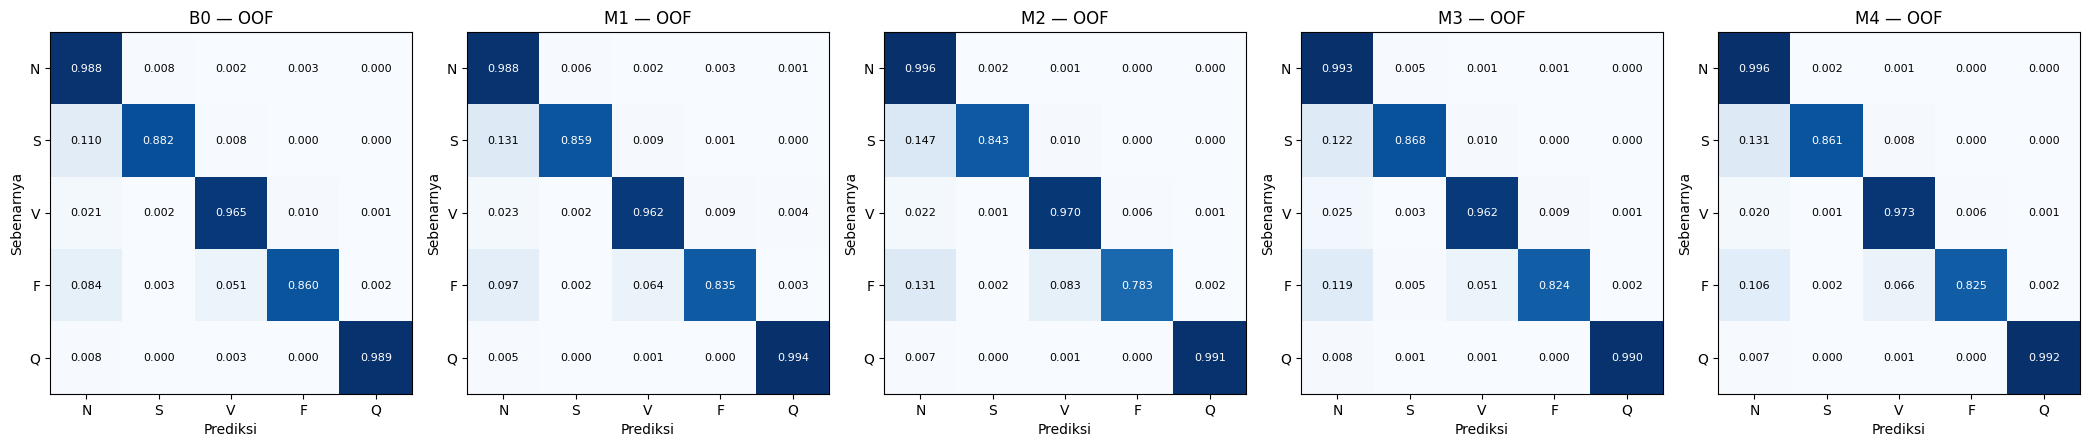

In [31]:
# ---- 1. Confusion matrix OOF (gabungan validation fold) ----
if len(RUNS):
    fig, axes = plt.subplots(1, len(order), figsize=(4.2 * len(order), 4.2))
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, order):
        cms = [np.array(r["val"]["cm"]) for r in RUNS if r["name"] == m]
        cm = sum(cms)
        row_sums = cm.sum(1, keepdims=True)
        cmn = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
        ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
        for i in range(5):
            for j in range(5):
                ax.text(j, i, f"{cmn[i, j]:.3f}", ha="center", va="center", fontsize=8,
                        color="white" if cmn[i, j] > 0.5 else "black")
        ax.set_xticks(range(5)); ax.set_yticks(range(5))
        ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
        ax.set_title(f"{m} — OOF")
    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "confusion_matrices_oof.png"), dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Belum ada hasil untuk confusion matrix.")


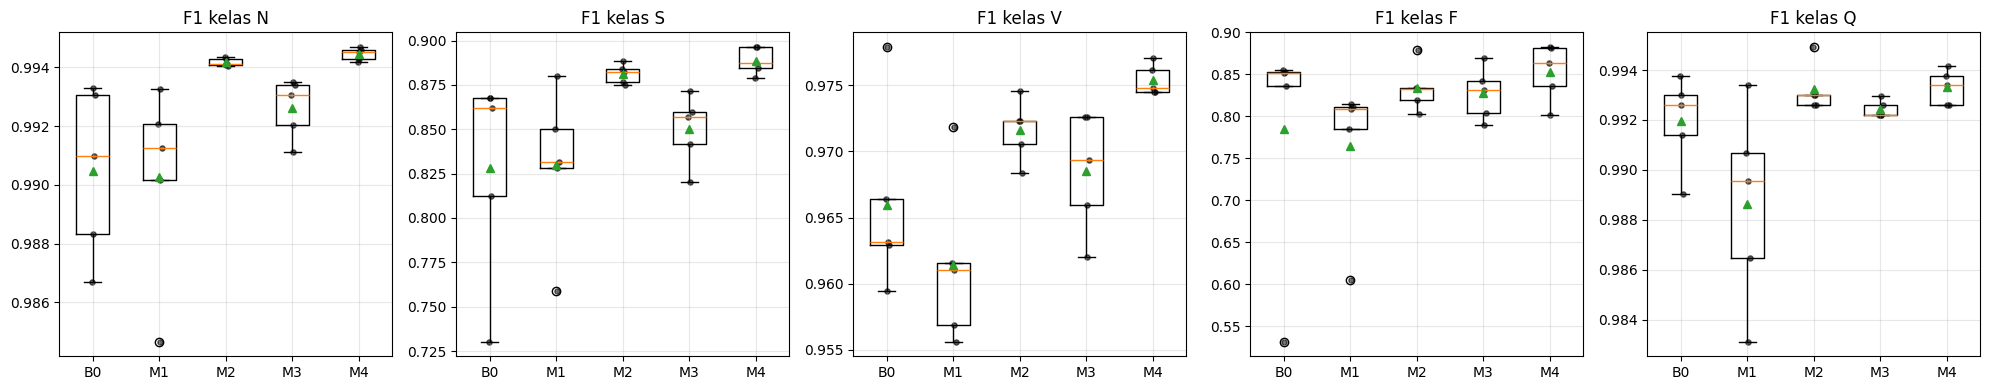

In [32]:
# ---- 2. Boxplot F1 per kelas (validation fold, antar fold) ----
if len(df):
    sub = df
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, c in zip(axes, CLASS_NAMES):
        data = [sub[sub.method == m][f"f1_{c}"].values for m in order]
        ax.boxplot(data, showmeans=True)
        ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
        for i, vals in enumerate(data, start=1):
            if len(vals):
                ax.scatter(np.full(len(vals), i) + np.random.RandomState(0).uniform(-0.08, 0.08, len(vals)), vals, s=14, alpha=0.6, color="k")
        ax.set_title(f"F1 kelas {c}"); ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "boxplot_f1_per_kelas_oof.png"), dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Belum ada hasil untuk boxplot.")


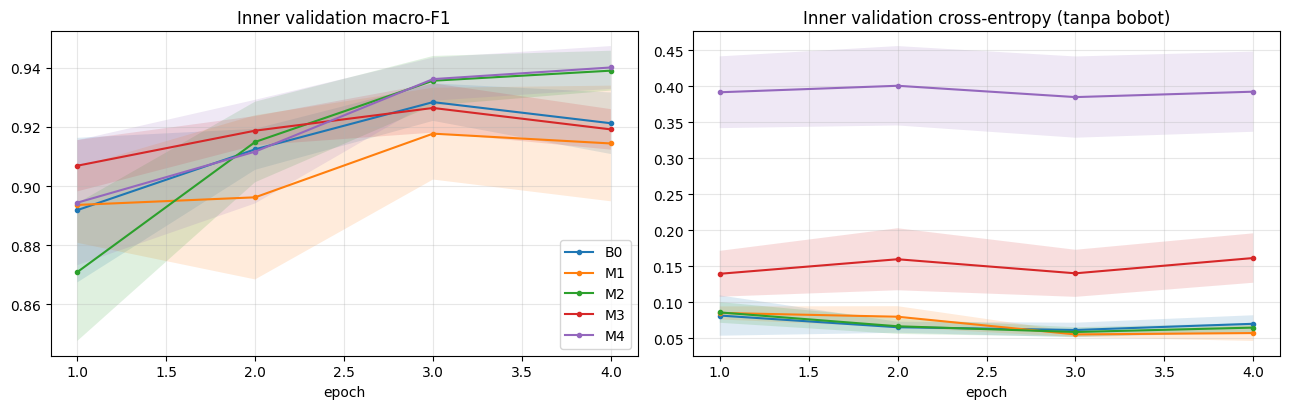

Recall per kelas (validation OOF, rata-rata antar fold):


,recall_N,recall_S,recall_V,recall_F,recall_Q
method,,,,,
B0,0.9875,0.8817,0.9653,0.8595,0.9890
M1,0.9877,0.8592,0.9620,0.8346,0.9938
M2,0.9964,0.8430,0.9698,0.7831,0.9911
M3,0.9927,0.8677,0.9623,0.8237,0.9900
M4,0.9960,0.8606,0.9729,0.8252,0.9922


In [33]:
# ---- 3. Kurva inner-validation (mean ± std antar outer fold) ----
if len(RUNS):
    warnings.filterwarnings("ignore", category=RuntimeWarning)

    def curve_matrix(m, key):
        hs = [r["history"] for r in RUNS if r["name"] == m]
        L = max(len(h) for h in hs)
        M = np.full((len(hs), L), np.nan)
        for i, h in enumerate(hs):
            M[i, :len(h)] = [e[key] for e in h]
        return M

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, (key, title) in zip(axes, (("val_f1", "Inner validation macro-F1"), ("val_ce", "Inner validation cross-entropy (tanpa bobot)"))):
        for m in order:
            M = curve_matrix(m, key)
            mu, sd = np.nanmean(M, 0), np.nanstd(M, 0)
            x = np.arange(1, len(mu) + 1)
            ax.plot(x, mu, marker="o", ms=3, label=m)
            ax.fill_between(x, mu - sd, mu + sd, alpha=0.15)
        ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
    axes[0].legend()
    plt.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "kurva_validasi_oof.png"), dpi=150, bbox_inches="tight")
    plt.show()

    rec = df.groupby("method")[[f"recall_{c}" for c in CLASS_NAMES]].mean().reindex(order)
    print("Recall per kelas (validation OOF, rata-rata antar fold):")
    display(rec.round(4))
else:
    print("Belum ada hasil untuk kurva validasi.")


# 10. Analisis, Final Test, dan Keterbatasan

1. Pilih metode terbaik berdasarkan **rata-rata outer-validation macro-F1**, bukan test resmi. Periksa pula recall/F1 per kelas dan confusion matrix OOF.
2. Inner validation digunakan untuk memilih kandidat M3/M4 dan epoch semua metode. Outer validation hanya digunakan satu kali untuk estimasi performa fold.
3. Lima outer fold tetap memiliki data training yang saling tumpang tindih; statistik antar-fold harus dibaca hati-hati dan bukan bukti independen sempurna.
4. Split berdasarkan beat, bukan pasien/rekaman. Klaim generalisasi ke pasien baru tidak didukung tanpa ID pasien/rekaman dan group split.
5. Ruang lingkup tetap satu dataset, RP, ResNet18. Hasil tidak otomatis berlaku pada dataset/modalitas/arsitektur lain.
6. Anggaran tuning M3/M4 hanya dua kandidat per fold karena keterbatasan T4. Laporkan ruang pencarian yang terbatas ini sebagai keterbatasan.
7. Angka Week 1 (accuracy 0,9883; macro-F1 0,9337) bukan hasil yang dibandingkan secara berpasangan dengan nested CV ini.

**Final test resmi:** jalankan sel Final Test setelah seluruh outer fold lengkap dan metode terbaik ditentukan dari OOF. Test resmi tidak boleh dipakai untuk mengubah hyperparameter atau memilih metode.


# 11. Final Test resmi (jalankan satu kali)

Sel ini memilih metode dari rata-rata outer OOF, melakukan pemilihan konfigurasi/epoch dengan inner split pada seluruh data train, refit pada seluruh data train dengan SMOTE, lalu mengukur test resmi satu kali. Jangan jalankan ulang untuk memilih konfigurasi berdasarkan skor test.


In [34]:
# Cegah evaluasi test resmi berulang tanpa sengaja.
FINAL_PATH=os.path.join(W3_DIR,"final_test_result.json")
if os.path.exists(FINAL_PATH):
    raise RuntimeError(f"Hasil final test sudah ada di {FINAL_PATH}. Jangan evaluasi test ulang; baca file JSON tersebut.")

# Pastikan kelima fold untuk kelima metode tersedia sebelum final test.
complete=all(os.path.exists(os.path.join(RUN_DIR,f"{m}_fold{k}.json")) and
             os.path.exists(os.path.join(RUN_DIR,f"{m}_fold{k}_valpred.npy"))
             for m in METHOD_NAMES for k in range(N_FOLDS))
if not complete:
    raise RuntimeError("Outer Nested CV belum lengkap: jalankan seluruh 5 fold × 5 metode terlebih dahulu.")

# Pilih metode hanya dari outer validation.
outer_means={}
for m in METHOD_NAMES:
    vals=[json.load(open(os.path.join(RUN_DIR,f"{m}_fold{k}.json")))['val']['macro_f1'] for k in range(N_FOLDS)]
    outer_means[m]=float(np.mean(vals))
best_method=max(outer_means,key=outer_means.get)
print("Rata-rata outer OOF macro-F1:",outer_means)
print("Metode terpilih dari OOF:",best_method)

# Inner split final pada seluruh data train untuk memilih config dan epoch.
inner=StratifiedShuffleSplit(n_splits=1,test_size=INNER_VAL_SIZE,random_state=SEED+777)
fit_idx,val_idx=next(inner.split(X_orig,y_orig))
Xfit,yfit=X_orig[fit_idx],y_orig[fit_idx]
Xival,yival=X_orig[val_idx],y_orig[val_idx]
final_best=-1.; final_cfg=None; final_epoch=None
for ci,cfg in enumerate(candidate_configs(best_method)):
    score,epoch,hist=fit_inner(cfg,Xfit,yfit,Xival,yival,INNER_EPOCHS)
    print(f"Final inner candidate {ci+1}: macro-F1={score:.4f}; epoch={epoch}")
    if score>final_best:
        final_best,final_cfg,final_epoch=score,cfg,epoch
final_epoch=min(max(1,int(final_epoch)),N_EPOCHS)

# Refitting pada seluruh train resmi (SMOTE hanya di train).
Xtrain_sm,ytrain_sm,train_counts=smote_resample(X_orig,y_orig,SEED+999)
Xtrain_t=torch.as_tensor(Xtrain_sm,dtype=torch.float32,device=DEVICE)
ytrain_t=torch.as_tensor(ytrain_sm,dtype=torch.long,device=DEVICE)
set_seed(SEED+1001)
net,groups=build_model(final_cfg["dropout"]); crit=build_loss(final_cfg,train_counts)
steps=math.ceil(len(Xtrain_t)/BATCH_SIZE)
opt,skind,sched=build_optimizer(final_cfg,groups,steps,final_epoch)
scaler=torch.amp.GradScaler("cuda",enabled=USE_AMP)
for ep in range(final_epoch):
    net.train(); perm=torch.randperm(len(Xtrain_t),device=DEVICE)
    for start in range(0,len(Xtrain_t),BATCH_SIZE):
        idx=perm[start:start+BATCH_SIZE]
        with torch.autocast("cuda",dtype=torch.float16,enabled=USE_AMP):
            logits=net(rp_batch(Xtrain_t[idx]))
        loss=crit(logits,ytrain_t[idx]); opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        if skind=="step": sched.step()
    if skind=="epoch": sched.step()

# Load and evaluate official test set exactly once.
X_test=np.load(os.path.join(FEATURES_DIR,"X_test.npy"),mmap_mode="r")
y_test=np.load(os.path.join(FEATURES_DIR,"y_test.npy")).astype(np.int64)
assert len(X_test)==len(y_test)
test_logits=predict_logits(net,X_test)
test_metrics,test_pred=compute_metrics(test_logits,y_test)
final_result=dict(selected_method=best_method,outer_oof_macro_f1=outer_means,
    final_inner_config=final_cfg,final_epoch=final_epoch,inner_selection_macro_f1=final_best,
    test_metrics=test_metrics,protocol="single_official_test_evaluation_after_nested_cv")
final_path=FINAL_PATH
json.dump(final_result,open(final_path,"w"),indent=2)
np.save(os.path.join(W3_DIR,"final_test_predictions.npy"),test_pred.astype(np.int8))
print("FINAL TEST — hasil satu kali evaluasi")
print({k:test_metrics[k] for k in ("accuracy","macro_precision","macro_recall","macro_f1")})
print("Disimpan:",final_path)


Rata-rata outer OOF macro-F1: {'B0': 0.9123851730644311, 'M1': 0.9070584733659681, 'M2': 0.9347661613515962, 'M3': 0.9262032601988466, 'M4': 0.9410095266509788}
Metode terpilih dari OOF: M4
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 151MB/s]


Final inner candidate 1: macro-F1=0.9391; epoch=4
Final inner candidate 2: macro-F1=0.9388; epoch=4


/tmp/ipykernel_973/158828630.py:8: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  xb=torch.as_tensor(X[i:i+bs], dtype=torch.float32, device=DEVICE)


FINAL TEST — hasil satu kali evaluasi
{'accuracy': 0.9885803033071442, 'macro_precision': 0.9476251600137757, 'macro_recall': 0.9173312074446649, 'macro_f1': 0.9317631671147494}
Disimpan: /content/drive/MyDrive/ECG_Multimodal_Fusion_Outputs/week3/final_test_result.json
